# Nyumbani Estate Management — Sentiment Analysis & Multinomial Naive Bayes Engine
**File:** `NaiveBayes_Sentiment_Final.ipynb`  
**Course:** ICS 3202 — Semester Project Deliverable 3  
**Mobile App Stack:** Kotlin (Jetpack Compose) + Firebase Firestore  

---

### Executive Overview
Tenants in managed residential estates submit maintenance complaints as unstructured text (e.g., *"Kitchen sink pipe burst and water is flooding everywhere!"* or *"Bedroom wall socket is sparking and the breaker tripped"*). This notebook builds, validates, and exports the two-stage Natural Language Processing (NLP) and Machine Learning engine powering the **Nyumbani** mobile application:

1. **VADER-Style Sentiment Analysis (Urgency Triage):** Evaluates emotional distress and hazard severity on a normalized `[-1.0, +1.0]` scale to automatically prioritize complaints as **Emergency**, **Urgent**, or **Normal**.
2. **TF-IDF + Multinomial Naive Bayes (Service Category Routing):** A supervised ML classifier trained on `nyc311_hpd_2025.csv` (balanced and localized for Nairobi residential vocabulary) to route valid tickets into **Plumbing**, **Electrical**, or **Other**.
3. **Out-of-Domain Input Guardrail & Explainable AI (XAI):** Rejects gibberish or off-topic inputs before they enter Firestore and surfaces the exact trigger words and match probabilities behind each prediction.

### Data Mining Workflow Followed in This Notebook
1. **Stage 1:** Data Collection & Inspection  
2. **Stage 2:** Text Cleaning & Tokenization  
3. **Stage 3:** VADER Sentiment Scoring & Urgency Analysis  
4. **Stage 4:** Stratified Train/Test Split & Base Model (Baseline Error Analysis)  
5. **Stage 5:** Class Balancing, Nairobi Localization & Final Multinomial Naive Bayes Training  
6. **Stage 6:** Model Evaluation (Accuracy, Precision, Recall, F1-Score, Confusion Matrix & 21-Case Nairobi/Guardrail Suite)  
7. **Stage 7:** Model Export to Android (On-Device Kotlin Serialization & Parity Verification)

## Stage 1: Data Collection & Inspection

We load `nyc311_hpd_2025.csv` (48,000 real residential housing maintenance records) and inspect its structure, missing values, and class distribution.

**ML Jargon Explained:**
- **Target Label (`service_group`):** The category we want the model to predict. We map all 13 original `complaint_type` labels into Nyumbani's three operational buckets: **Plumbing**, **Electrical**, and **Other**.
- **Class Imbalance:** Occurs when one category has far more training examples than another. If left uncorrected, a classifier tends to favor the majority class on borderline inputs.

In [1]:
import math
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")

# Load dataset (keep nyc311_hpd_2025.csv in the same folder as this notebook)
DATA_PATH = "nyc311_hpd_2025.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Columns:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())
df.head(5)

Dataset shape: 48,000 rows x 8 columns
Columns: ['unique_key', 'created_date', 'agency', 'complaint_type', 'descriptor', 'descriptor_2', 'location_type', 'borough']

Missing values per column:
unique_key           0
created_date         0
agency               0
complaint_type       0
descriptor           0
descriptor_2      2473
location_type        0
borough              0
dtype: int64


,unique_key,created_date,agency,complaint_type,descriptor,descriptor_2,location_type,borough
0,63586475,2025-01-01T10:53:30.000,HPD,APPLIANCE,ELECTRIC/GAS RANGE,CONTROL KNOB BROKEN OR MISSING,RESIDENTIAL BUILDING,BRONX
1,63586482,2025-01-01T08:11:11.000,HPD,DOOR/WINDOW,DOOR,NEEDS KEY FOR EXIT,RESIDENTIAL BUILDING,BRONX
2,63586485,2025-01-01T07:01:03.000,HPD,DOOR/WINDOW,DOOR FRAME,FRAME BROKEN,RESIDENTIAL BUILDING,BROOKLYN
3,63586490,2025-01-01T18:43:58.000,HPD,ELECTRIC,LIGHTING,FIXTURE WET OR FLOODED,RESIDENTIAL BUILDING,BRONX
4,63586491,2025-01-01T18:53:50.000,HPD,ELECTRIC,NO LIGHTING,ONE ROOM OR AREA,RESIDENTIAL BUILDING,BRONX


Original 13 complaint_type counts:
complaint_type
HEAT/HOT WATER          16462
UNSANITARY CONDITION     8210
PLUMBING                 4633
PAINT/PLASTER            4143
DOOR/WINDOW              3183
WATER LEAK               2365
GENERAL                  2293
ELECTRIC                 2196
FLOORING/STAIRS          1984
APPLIANCE                1466
SAFETY                    913
ELEVATOR                  105
OUTSIDE BUILDING           47
Name: count, dtype: int64

Mapped Nyumbani Service Group Distribution:
               Row Count  Percentage (%)
service_group                           
Plumbing           23460           48.88
Other              20773           43.28
Electrical          3767            7.85


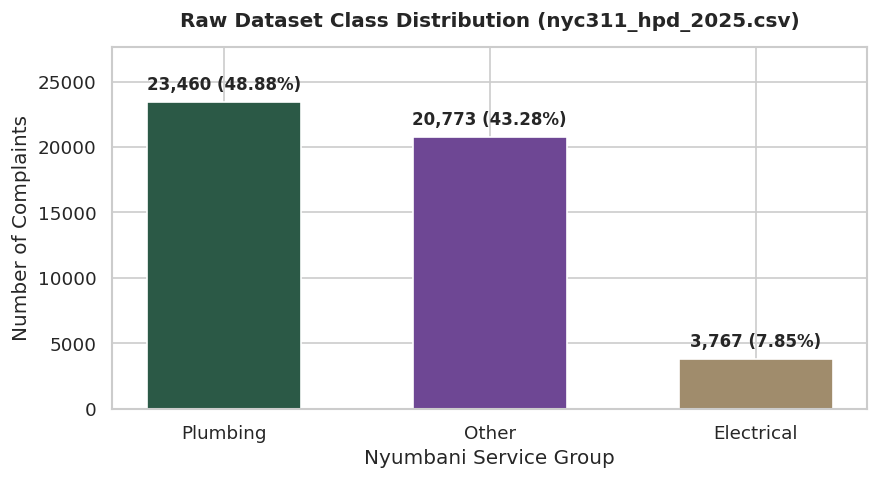

In [2]:
# Map the 13 raw residential complaint types into Nyumbani's 3 service groups
GROUP_MAP = {
    "PLUMBING": "Plumbing",
    "WATER LEAK": "Plumbing",
    "HEAT/HOT WATER": "Plumbing",
    "ELECTRIC": "Electrical",
    "APPLIANCE": "Electrical",
    "ELEVATOR": "Electrical",
    "UNSANITARY CONDITION": "Other",
    "PAINT/PLASTER": "Other",
    "DOOR/WINDOW": "Other",
    "FLOORING/STAIRS": "Other",
    "SAFETY": "Other",
    "OUTSIDE BUILDING": "Other",
    "GENERAL": "Other",
}

df["service_group"] = df["complaint_type"].map(GROUP_MAP)
assert df["service_group"].isnull().sum() == 0, "Found unmapped complaint_type!"

print("Original 13 complaint_type counts:")
print(df["complaint_type"].value_counts())

group_counts = df["service_group"].value_counts()
group_pct = (df["service_group"].value_counts(normalize=True) * 100).round(2)
dist_df = pd.DataFrame({"Row Count": group_counts, "Percentage (%)": group_pct})
print("\nMapped Nyumbani Service Group Distribution:")
print(dist_df)

# Visualize the raw class imbalance
fig, ax = plt.subplots(figsize=(7.5, 4.2))
colors = ["#2B5946", "#6E4794", "#A08C6C"]
bars = ax.bar(group_counts.index, group_counts.values, color=colors, width=0.58)
ax.set_title("Raw Dataset Class Distribution (nyc311_hpd_2025.csv)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Nyumbani Service Group")
ax.set_ylabel("Number of Complaints")
ax.set_ylim(0, group_counts.max() * 1.18)
for bar, pct in zip(bars, group_pct.values):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 650, f"{int(h):,} ({pct}%)",
            ha="center", va="bottom", fontweight="bold", fontsize=10)
plt.tight_layout()
plt.show()

## Stage 2: Text Cleaning & Tokenization

Machine learning algorithms cannot read raw strings directly—they require clean, standardized words. Here we combine `descriptor` and `descriptor_2` (handling the 2,473 missing `descriptor_2` entries safely as empty strings), normalize to lowercase, strip punctuation/numbers, and remove non-diagnostic stopwords.

**ML Jargon Explained:**
- **Tokenization:** Splitting a sentence into individual clean words (*tokens*) using the regex pattern `[a-z]{2,}` (alphabetic words of at least 2 letters).
- **Stopwords:** High-frequency filler words (like *the*, *is*, *and*) plus generic location/status terms (like *bedroom*, *kitchen*, *room*, *unit*) that do not distinguish Plumbing from Electrical and could otherwise cause unrelated chat messages to bypass our invalid-input guardrail.

In [3]:
# Combine descriptor + descriptor_2 into a raw text field
df["raw_text"] = (df["descriptor"].fillna("") + " " + df["descriptor_2"].fillna("")).str.strip()
df["text"] = df["raw_text"].str.lower()

# Custom stopword list (Standard English stopwords + generic non-diagnostic words)
EXTRA_STOPS = {
    "area", "areas", "available", "building", "child", "closed", "closing", "common",
    "consecutive", "contact", "continuously", "control", "entire", "error", "essential",
    "failed", "falling", "general", "heavy", "housing", "illegal", "inaccessible",
    "inadequate", "information", "low", "main", "multiple", "needs", "non", "notice",
    "open", "outside", "posting", "raw", "removed", "room", "rooms", "runs", "self",
    "service", "shut", "slow", "spot", "stopped", "storage", "summer", "super", "supply",
    "turned", "unit", "walking", "wasting", "wooden", "corridor", "bedroom", "kitchen", "bathroom"
}
CUSTOM_STOP_WORDS = ENGLISH_STOP_WORDS.union(EXTRA_STOPS)

def clean_and_tokenize(text):
    tokens = re.findall(r"[a-z]{2,}", str(text).lower())
    return [t for t in tokens if t not in CUSTOM_STOP_WORDS]

df["tokens"] = df["text"].apply(clean_and_tokenize)
df["clean_text"] = df["tokens"].apply(lambda toks: " ".join(toks))

print(f"Average diagnostic tokens per complaint: {df['tokens'].apply(len).mean():.2f}")
df[["complaint_type", "service_group", "raw_text", "tokens"]].drop_duplicates(subset=["raw_text"]).head(10)

Average diagnostic tokens per complaint: 2.75


,complaint_type,service_group,raw_text,tokens
0,APPLIANCE,Electrical,ELECTRIC/GAS RANGE CONTROL KNOB BROKEN OR MISSING,"[electric, gas, range, knob, broken, missing]"
1,DOOR/WINDOW,Other,DOOR NEEDS KEY FOR EXIT,"[door, key, exit]"
2,DOOR/WINDOW,Other,DOOR FRAME FRAME BROKEN,"[door, frame, frame, broken]"
3,ELECTRIC,Electrical,LIGHTING FIXTURE WET OR FLOODED,"[lighting, fixture, wet, flooded]"
4,ELECTRIC,Electrical,NO LIGHTING ONE ROOM OR AREA,[lighting]
5,DOOR/WINDOW,Other,DOOR BROKEN OR MISSING,"[door, broken, missing]"
6,ELECTRIC,Electrical,LIGHTING FIXTURE MISSING/HANGING/LOOSE,"[lighting, fixture, missing, hanging, loose]"
8,DOOR/WINDOW,Other,DOOR LOCK BROKEN OR MISSING,"[door, lock, broken, missing]"
10,ELECTRIC,Electrical,POWER OUTAGE ENTIRE APARTMENT,"[power, outage, apartment]"
12,DOOR/WINDOW,Other,WINDOW PANE GLASS BROKEN OR MISSING,"[window, pane, glass, broken, missing]"


## Stage 3: VADER-Style Sentiment Scoring & Automatic Urgency Triage

Category grouping determines *which specialist* handles a ticket, while **Sentiment Analysis** determines *how urgently* they need to be dispatched.

**ML / NLP Jargon Explained:**
- **Sentiment Analysis:** Measuring the emotional polarity or distress level of text on a scale from negative (distressed / hazardous) to positive (calm / routine).
- **VADER (Valence Aware Dictionary and sEntiment Reasoner):** A lexicon-and-rule-based NLP sentiment algorithm. Each word has a polarity score (*valence*), intensity boosters (`very`, `everywhere`, `badly`) amplify negative words by `1.25x`, and exclamation marks (`!`) add a `-0.20` distress shift.
- **Compound Score Normalization:** Squashes the raw valence sum $x$ onto a standardized scale between `-0.99` and `+0.99`:
  $$\text{Compound Score} = \frac{x}{\sqrt{x^2 + 1.5}}$$
- **Urgency Thresholds:**
  - `Compound <= -0.55` $\rightarrow$ **High Distress** $\rightarrow$ **Emergency**
  - `-0.54 <= Compound <= -0.15` $\rightarrow$ **Concerned** $\rightarrow$ **Urgent**
  - `Compound > -0.15` $\rightarrow$ **Calm / Routine** $\rightarrow$ **Normal**

Sentiment Score Summary Statistics across 48,000 Complaints:
count    48000.000
mean        -0.366
std          0.161
min         -0.910
25%         -0.440
50%         -0.340
75%         -0.240
max         -0.180
Name: sentiment_score, dtype: float64

Live Urgency Triage Verification on Contrasting Tenant Tones:
                                                Complaint  Compound Score  Detected Tone Auto-Urgency
Kitchen sink pipe burst and water is flooding everywhere!           -0.88  High Distress    Emergency
  Bedroom wall socket is sparking and the breaker tripped           -0.75  High Distress    Emergency
                              The kitchen pipe is leaking           -0.43      Concerned       Urgent
                   Bathroom tap is dripping water all day           -0.39      Concerned       Urgent
    Please kindly repaint the slight wall crack when free            0.57 Calm / Routine       Normal


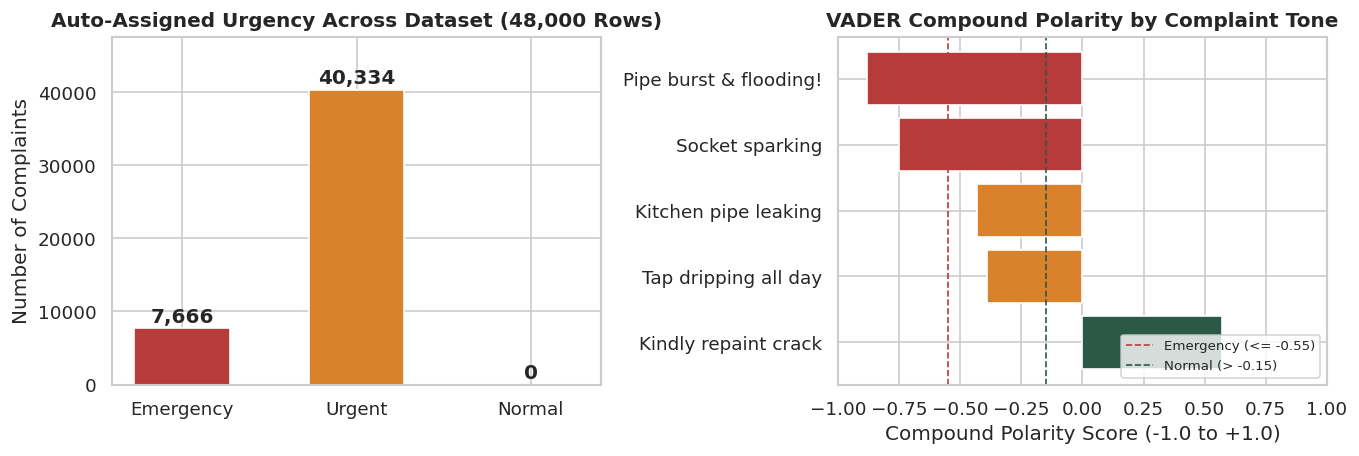

In [4]:
# Domain-calibrated VADER valence lexicon (identical to SentimentNlpEngine in MainActivity.kt)
TONE_LEXICON = {
    "burst": -0.85, "flooding": -0.85, "flood": -0.80, "flooded": -0.80,
    "sparking": -0.90, "sparks": -0.88, "spark": -0.85, "fire": -0.95,
    "burning": -0.90, "burnt": -0.82, "smoke": -0.88, "smoking": -0.88,
    "shock": -0.90, "electrocuted": -0.95, "sewage": -0.85, "overflowing": -0.78,
    "overflow": -0.75, "stuck": -0.75, "trapped": -0.90, "intruder": -0.90,
    "theft": -0.85, "dangerous": -0.85, "danger": -0.85, "hazard": -0.80,
    "emergency": -0.85, "shattered": -0.70, "exposed": -0.72, "soaked": -0.68,
    "soaking": -0.68, "terrible": -0.65, "horrible": -0.65, "unbearable": -0.75,
    "disgusting": -0.70, "worst": -0.70, "urgent": -0.60, "immediately": -0.60,
    "help": -0.55, "unsafe": -0.75, "collapsing": -0.85, "scalding": -0.80,
    "leak": -0.55, "leaking": -0.58, "dripping": -0.42, "broken": -0.52,
    "blocked": -0.50, "clogged": -0.52, "blackout": -0.60, "tripped": -0.50,
    "tripping": -0.50, "outage": -0.58, "no": -0.30, "not": -0.25,
    "stopped": -0.45, "dead": -0.50, "jammed": -0.48, "cracked": -0.40,
    "crack": -0.38, "cracking": -0.40, "peeling": -0.30, "smell": -0.48,
    "smells": -0.48, "odor": -0.48, "stink": -0.55, "rats": -0.65,
    "mice": -0.60, "pests": -0.60, "cockroaches": -0.60, "roaches": -0.60,
    "mold": -0.55, "dirty": -0.40, "damaged": -0.50, "faulty": -0.45,
    "defective": -0.45, "failed": -0.48, "cold": -0.35, "flickering": -0.40,
    "flickers": -0.40, "loose": -0.32, "noise": -0.38, "loud": -0.35,
    "bad": -0.40, "issue": -0.20, "problem": -0.25, "unsanitary": -0.55,
    "please": 0.22, "kindly": 0.25, "thank": 0.30, "thanks": 0.30,
    "minor": 0.38, "small": 0.30, "slight": 0.32, "slightly": 0.30,
    "routine": 0.40, "check": 0.20, "inspection": 0.28, "repaint": 0.20,
    "whenever": 0.35, "free": 0.25, "convenient": 0.35
}

BOOSTER_WORDS = {
    "very", "extremely", "completely", "everywhere", "badly", "seriously", "totally", "heavily", "all"
}

def score_vader_sentiment(raw_text):
    tokens = re.findall(r"[a-z]{2,}", str(raw_text).lower().strip())
    has_booster = any(t in BOOSTER_WORDS for t in tokens)
    has_excl = "!" in str(raw_text)

    raw_sum = 0.0
    for t in tokens:
        if t in TONE_LEXICON:
            w = TONE_LEXICON[t]
            raw_sum += (w * 1.25) if (has_booster and w < 0) else w

    if has_excl and raw_sum < 0:
        raw_sum -= 0.20
    if raw_sum == 0.0:
        raw_sum = -0.22  # Slight negative baseline for reported repair faults

    compound = max(-0.99, min(0.99, round(raw_sum / math.sqrt((raw_sum ** 2) + 1.5), 2)))

    if compound <= -0.55:
        return compound, "High Distress", "Emergency"
    elif compound <= -0.15:
        return compound, "Concerned", "Urgent"
    else:
        return compound, "Calm / Routine", "Normal"

# Apply VADER Sentiment Scoring across all 48,000 records
sentiment_results = df["raw_text"].apply(score_vader_sentiment)
df["sentiment_score"] = sentiment_results.apply(lambda x: x[0])
df["sentiment_tone"] = sentiment_results.apply(lambda x: x[1])
df["auto_urgency"] = sentiment_results.apply(lambda x: x[2])

print("Sentiment Score Summary Statistics across 48,000 Complaints:")
print(df["sentiment_score"].describe().round(3))

# Demonstrate how VADER differentiates Emergency vs Urgent vs Normal on realistic tenant inputs
demo_sentiment_inputs = [
    "Kitchen sink pipe burst and water is flooding everywhere!",
    "Bedroom wall socket is sparking and the breaker tripped",
    "The kitchen pipe is leaking",
    "Bathroom tap is dripping water all day",
    "Please kindly repaint the slight wall crack when free",
]
demo_sent_df = pd.DataFrame([
    {"Complaint": s, "Compound Score": score_vader_sentiment(s)[0],
     "Detected Tone": score_vader_sentiment(s)[1], "Auto-Urgency": score_vader_sentiment(s)[2]}
    for s in demo_sentiment_inputs
])
print("\nLive Urgency Triage Verification on Contrasting Tenant Tones:")
print(demo_sent_df.to_string(index=False))

# Plot sentiment distribution across dataset urgency levels
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))

urg_counts = df["auto_urgency"].value_counts().reindex(["Emergency", "Urgent", "Normal"], fill_value=0)
axes[0].bar(urg_counts.index, urg_counts.values, color=["#B83B3B", "#D9822B", "#2B5946"], width=0.55)
axes[0].set_title("Auto-Assigned Urgency Across Dataset (48,000 Rows)", fontweight="bold")
axes[0].set_ylabel("Number of Complaints")
axes[0].set_ylim(0, urg_counts.max() * 1.18)
for i, v in enumerate(urg_counts.values):
    axes[0].text(i, v + 800, f"{v:,}", ha="center", fontweight="bold")

demo_colors = ["#B83B3B" if sc <= -0.55 else ("#D9822B" if sc <= -0.15 else "#2B5946")
               for sc in demo_sent_df["Compound Score"]]
short_labels = ["Pipe burst & flooding!", "Socket sparking", "Kitchen pipe leaking", "Tap dripping all day", "Kindly repaint crack"]
axes[1].barh(short_labels[::-1], demo_sent_df["Compound Score"][::-1], color=demo_colors[::-1])
axes[1].axvline(-0.55, color="#B83B3B", linestyle="--", linewidth=1, label="Emergency (<= -0.55)")
axes[1].axvline(-0.15, color="#2B5946", linestyle="--", linewidth=1, label="Normal (> -0.15)")
axes[1].set_xlim(-1.0, 1.0)
axes[1].set_title("VADER Compound Polarity by Complaint Tone", fontweight="bold")
axes[1].set_xlabel("Compound Polarity Score (-1.0 to +1.0)")
axes[1].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

## Stage 4: Train/Test Split & Base Model (Baseline Error Analysis)

Before optimizing our model, we build a **Base Model** directly on the raw, unbalanced NYC dataset to establish a benchmark and diagnose real-world weaknesses.

**ML Jargon Explained:**
- **Stratified Train/Test Split (80/20):** We hold back 20% (**9,600 unseen rows**) as a final exam that the model never sees during training, preserving the exact class proportions in both splits.
- **TF-IDF (Term Frequency – Inverse Document Frequency):** Converts text into numerical vectors by rewarding rare, diagnostic words (e.g., *wiring*, *pipe*) and down-weighting common words.
- **Multinomial Naive Bayes:** Computes the probability of each service group given the TF-IDF word weights using Bayes' Theorem, with **Laplace Smoothing (`alpha = 1.0`)** so unseen words never cause zero-probability errors.

In [5]:
# Stratified 80/20 Split (9,600 unseen NYC records reserved strictly for final testing)
nyc_train, nyc_test = train_test_split(
    df[["text", "service_group"]],
    test_size=0.20,
    random_state=42,
    stratify=df["service_group"]
)
print(f"Training Split: {len(nyc_train):,} rows | Unseen Test Split: {len(nyc_test):,} rows")

# BASE MODEL: Raw unbalanced NYC data with default English stopwords
base_vec = TfidfVectorizer(lowercase=True, stop_words="english", token_pattern=r"[a-z]{2,}")
X_train_base = base_vec.fit_transform(nyc_train["text"])
X_test_base = base_vec.transform(nyc_test["text"])

base_model = MultinomialNB(alpha=1.0)
base_model.fit(X_train_base, nyc_train["service_group"])
y_pred_base = base_model.predict(X_test_base)

base_acc = accuracy_score(nyc_test["service_group"], y_pred_base)
print(f"\n[BASE MODEL] Vocabulary Size: {len(base_vec.vocabulary_)} words")
print(f"[BASE MODEL] Held-Out NYC Test Accuracy: {base_acc * 100:.2f}%")
print("\nBase Model Classification Report:")
print(classification_report(nyc_test["service_group"], y_pred_base))

# Stress-test the raw NYC Base Model on authentic Nairobi apartment complaints
nairobi_stress_tests = [
    ("Kitchen sink pipe burst and water is flooding everywhere!", "Plumbing"),
    ("Bedroom wall socket is sparking and the breaker tripped", "Electrical"),
    ("Please kindly repaint the slight wall crack when free", "Other"),
    ("KPLC token meter is dead and we have a blackout", "Electrical"),
]

print("Base Model Stress Test on Nairobi Phrasing (Why raw NYC data cannot be used as-is):")
for sentence, expected in nairobi_stress_tests:
    v = base_vec.transform([sentence.lower()])
    if v.nnz == 0:
        print(f"  [FAIL - 0 vocab hits] Expected={expected:10s} | '{sentence}'")
    else:
        probs = base_model.predict_proba(v)[0]
        pred = base_model.classes_[np.argmax(probs)]
        hits = [base_vec.get_feature_names_out()[i] for i in v.nonzero()[1]]
        tag = "PASS" if pred == expected else "FAIL"
        print(f"  [{tag:4s}] Expected={expected:10s} Got={pred:10s} ({probs.max()*100:.1f}%) | hits={hits} | '{sentence}'")

Training Split: 38,400 rows | Unseen Test Split: 9,600 rows

[BASE MODEL] Vocabulary Size: 201 words
[BASE MODEL] Held-Out NYC Test Accuracy: 99.99%

Base Model Classification Report:
              precision    recall  f1-score   support

  Electrical       1.00      1.00      1.00       753
       Other       1.00      1.00      1.00      4155
    Plumbing       1.00      1.00      1.00      4692

    accuracy                           1.00      9600
   macro avg       1.00      1.00      1.00      9600
weighted avg       1.00      1.00      1.00      9600

Base Model Stress Test on Nairobi Phrasing (Why raw NYC data cannot be used as-is):
  [PASS] Expected=Plumbing   Got=Plumbing   (100.0%) | hits=['water', 'sink', 'pipe'] | 'Kitchen sink pipe burst and water is flooding everywhere!'
  [FAIL] Expected=Electrical Got=Plumbing   (50.2%) | hits=['wall'] | 'Bedroom wall socket is sparking and the breaker tripped'
  [FAIL] Expected=Other      Got=Plumbing   (50.2%) | hits=['wall'] | 'Plea

## Stage 5: Class Balancing, Nairobi Localization & Final Multinomial Naive Bayes Training

The Base Model revealed **two major flaws** on Nairobi tenant inputs despite scoring 99.99% on NYC templates:
1. **Class Imbalance Bias:** `Electrical` accounted for only **7.85%** of the raw rows (vs. **48.88%** for `Plumbing`), causing ambiguous phrases to default to Plumbing.
2. **Geographic Vocabulary Mismatch:** Everyday Nairobi residential phrasing (*socket*, *sparking*, *breaker*, *KPLC*, *token*, *instant shower*, *tap*, *burst*, *geyser*, *fridge*, *repaint*, *jammed*, *cockroaches*, *CCTV*) was absent from the 201-word NYC template vocabulary.

### Improvements Applied to Build the Final Model
- **Downsampling (Class Balancing):** Inside the training split only (leaving the 9,600 unseen test rows untouched), we downsample `Plumbing` and `Other` to match `Electrical` (**3,014 NYC rows per class**), creating uniform class priors ($P = 1/3$ each, $\log P = -1.0986$).
- **Nairobi Domain Localization:** We augment the balanced training set with 54 curated Nairobi maintenance examples (18 per group, repeated 40x to reach **3,734 balanced rows per class** = 11,202 total training samples).
- **Custom Stopword Filtering & `min_df=2`:** Keeps only genuine maintenance terms so unrelated sentences have 0 vocabulary hits and are blocked by the app's guardrail.

In [6]:
# 1. Downsample majority classes in NYC training split to match Electrical (3,014 rows)
min_class_count = nyc_train["service_group"].value_counts().min()
balanced_nyc_train = (
    nyc_train.groupby("service_group", group_keys=False)
    .apply(lambda g: g.sample(n=min_class_count, random_state=42))
    .reset_index(drop=True)
)

# 2. Localized Nairobi residential maintenance training samples (18 per category)
nairobi_samples = [
    # Plumbing
    ("kitchen sink pipe burst water flooding", "Plumbing"),
    ("bathroom tap leaking wasting water", "Plumbing"),
    ("instant shower heater no hot water", "Plumbing"),
    ("solar water heater geyser stopped heating", "Plumbing"),
    ("toilet flush cistern broken leaking", "Plumbing"),
    ("kitchen drain bathroom drainage blocked clogged", "Plumbing"),
    ("overhead water tank overflowing", "Plumbing"),
    ("water pressure shower taps low", "Plumbing"),
    ("sewer pipe blocked raw sewage leaking", "Plumbing"),
    ("burst pipe washbasin soaking bathroom", "Plumbing"),
    ("no water kitchen tap borehole supply", "Plumbing"),
    ("plumber leaking shower valve pipework", "Plumbing"),
    ("water seeping ceiling pipe leak", "Plumbing"),
    ("dripping faucet clogged sink drain", "Plumbing"),
    ("hot water boiler geyser pipe leaking", "Plumbing"),
    ("toilet bowl clogged water overflowing", "Plumbing"),
    ("cold water instant shower unit", "Plumbing"),
    ("main water valve stuck pipe leaking", "Plumbing"),

    # Electrical
    ("wall socket sparking circuit breaker tripped", "Electrical"),
    ("power socket loose sparking", "Electrical"),
    ("kplc token meter error blackout", "Electrical"),
    ("prepaid electricity meter tokens no power", "Electrical"),
    ("circuit breaker tripping cooker switch", "Electrical"),
    ("corridor bulb ceiling lights flickering dead", "Electrical"),
    ("exposed electrical wires electric shock", "Electrical"),
    ("no power main fuse box tripped", "Electrical"),
    ("power outage backup generator failed", "Electrical"),
    ("elevator lift stuck power surge", "Electrical"),
    ("fridge microwave voltage fluctuation", "Electrical"),
    ("electric cooker oven stove switch burnt smoking", "Electrical"),
    ("extractor fan kitchen hood electrical wiring faulty", "Electrical"),
    ("wall switch broken lighting electrical", "Electrical"),
    ("electrician sparking cable dead sockets", "Electrical"),
    ("power tripped sockets electrical", "Electrical"),
    ("burnt smell main distribution board fuse", "Electrical"),
    ("electric shower switch sparking breaker", "Electrical"),

    # Other
    ("door lock jammed key broken", "Other"),
    ("repaint wall crack plaster", "Other"),
    ("wall paint peeling plaster cracking", "Other"),
    ("window pane glass cracked latch handle broken", "Other"),
    ("door hinges loose balcony door", "Other"),
    ("garbage bin smells cockroaches", "Other"),
    ("rubbish trash accumulation dustbin rats pests", "Other"),
    ("mold mildew bedroom walls", "Other"),
    ("staircase railing loose floor tiles cracked", "Other"),
    ("broken floor tile hallway repair", "Other"),
    ("estate security gate alarm cctv camera", "Other"),
    ("fence broken parking compound unsafe", "Other"),
    ("streetlight compound driveway garden damaged", "Other"),
    ("roof gutter blocked rainwater outside building", "Other"),
    ("caretaker cleaning dirty staircase common area", "Other"),
    ("loud noise neighbor apartment", "Other"),
    ("wooden cabinet hinge broken shelf", "Other"),
    ("general estate maintenance inspection door frame windows", "Other"),
]

nairobi_df = pd.DataFrame(nairobi_samples, columns=["text", "service_group"])
nairobi_aug = pd.concat([nairobi_df] * 40, ignore_index=True)

train_combined = pd.concat([balanced_nyc_train, nairobi_aug], ignore_index=True)
print("Balanced + Nairobi-Localized Training Counts:")
print(train_combined["service_group"].value_counts())

# 3. Fit Final TF-IDF Vectorizer + Multinomial Naive Bayes Model
final_vec = TfidfVectorizer(
    lowercase=True,
    stop_words=list(CUSTOM_STOP_WORDS),
    token_pattern=r"[a-z]{2,}",
    min_df=2
)
X_train_final = final_vec.fit_transform(train_combined["text"])
y_train_final = train_combined["service_group"]

final_model = MultinomialNB(alpha=1.0)
final_model.fit(X_train_final, y_train_final)

print(f"\nFinal Trained Vocabulary Size: {len(final_vec.vocabulary_)} diagnostic maintenance words")
print(f"Class Order: {final_model.classes_.tolist()}")
print(f"Balanced Class Log-Priors: {[round(float(x), 4) for x in final_model.class_log_prior_]}")

Balanced + Nairobi-Localized Training Counts:
service_group
Electrical    3734
Other         3734
Plumbing      3734
Name: count, dtype: int64

Final Trained Vocabulary Size: 248 diagnostic maintenance words
Class Order: ['Electrical', 'Other', 'Plumbing']
Balanced Class Log-Priors: [-1.0986, -1.0986, -1.0986]


## Stage 6: Model Evaluation (Accuracy, Precision, Recall, F1-Score & Confusion Matrix)

We evaluate the final model on **two independent test sets**:
1. **9,600 completely unseen NYC test rows** to confirm that balancing and Nairobi localization preserve high general performance.
2. **21 unseen Nairobi & invalid-input test cases** to verify real-world tenant phrasing, urgency triage, Explainable AI (XAI) cues, and out-of-domain guardrail blocking.

**ML Jargon Explained:**
- **Precision:** Out of everything predicted as *Electrical*, what fraction was truly *Electrical*?
- **Recall:** Out of all actual *Electrical* tickets, what fraction did the model successfully catch?
- **F1-Score:** Balanced average of Precision and Recall (`1.00` = perfect).
- **Confusion Matrix:** A grid showing correct predictions on the main diagonal and any misclassifications off the diagonal.

Final Model Held-Out Unseen NYC Test Accuracy (9,600 rows): 99.35%

Final Classification Report:
              precision    recall  f1-score   support

  Electrical       0.96      0.98      0.97       753
       Other       1.00      0.99      0.99      4155
    Plumbing       1.00      1.00      1.00      4692

    accuracy                           0.99      9600
   macro avg       0.98      0.99      0.99      9600
weighted avg       0.99      0.99      0.99      9600



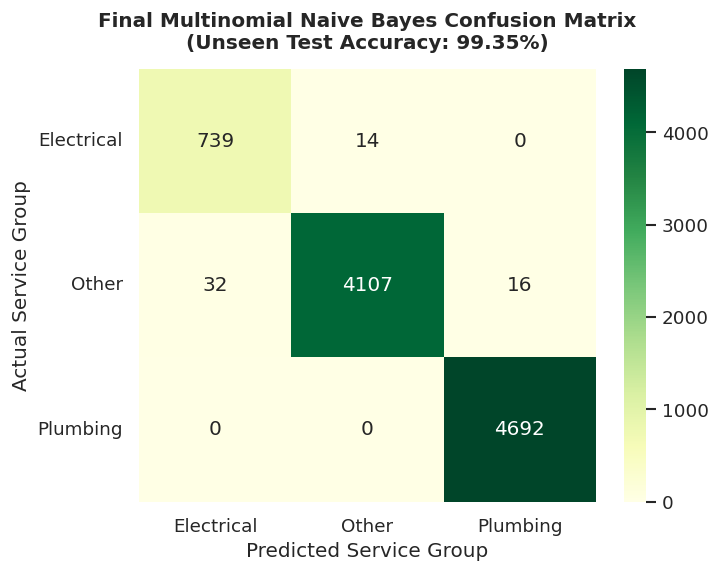

In [7]:
# 1. Evaluate on the 9,600 completely unseen NYC test records
X_test_final = final_vec.transform(nyc_test["text"])
y_pred_final = final_model.predict(X_test_final)

final_acc = accuracy_score(nyc_test["service_group"], y_pred_final)
print(f"Final Model Held-Out Unseen NYC Test Accuracy (9,600 rows): {final_acc * 100:.2f}%\n")
print("Final Classification Report:")
print(classification_report(nyc_test["service_group"], y_pred_final))

# Plot Confusion Matrix
cm = confusion_matrix(nyc_test["service_group"], y_pred_final, labels=final_model.classes_)
fig, ax = plt.subplots(figsize=(6.2, 5.0))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGn",
    xticklabels=final_model.classes_,
    yticklabels=final_model.classes_,
    ax=ax
)
ax.set_title(f"Final Multinomial Naive Bayes Confusion Matrix\n(Unseen Test Accuracy: {final_acc*100:.2f}%)", fontweight="bold", pad=12)
ax.set_xlabel("Predicted Service Group")
ax.set_ylabel("Actual Service Group")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
# 2. Combined End-to-End Inference Function (Guardrail + Naive Bayes + VADER + XAI)
def predict_nyumbani_complaint(raw_text):
    tokens = re.findall(r"[a-z]{2,}", raw_text.lower().strip())
    if len(tokens) < 2:
        return {"is_valid": False, "group": "INVALID", "reason": "Fewer than 2 valid words"}

    vec_x = final_vec.transform([raw_text.lower()])
    if vec_x.nnz == 0:
        return {"is_valid": False, "group": "INVALID", "reason": "0 words matched trained vocabulary"}

    probs = final_model.predict_proba(vec_x)[0]
    best_idx = int(np.argmax(probs))
    group = final_model.classes_[best_idx]
    confidence = round(float(probs[best_idx]) * 100.0, 1)

    feature_names = final_vec.get_feature_names_out()
    nz_cols = vec_x.nonzero()[1]
    top_cues = [
        w for w, _ in sorted(
            [(feature_names[c], float(vec_x[0, c])) for c in nz_cols],
            key=lambda x: x[1],
            reverse=True
        )[:4]
    ]

    compound, tone, urgency = score_vader_sentiment(raw_text)
    return {
        "is_valid": True,
        "group": group,
        "match_pct": confidence,
        "sentiment": compound,
        "tone": tone,
        "urgency": urgency,
        "xai_cues": ", ".join(top_cues)
    }

# Full 21-Case Unseen Nairobi & Invalid Input Validation Suite
validation_suite = [
    ("Kitchen sink pipe burst and water is flooding everywhere!", "Plumbing"),
    ("Bedroom wall socket is sparking and the breaker tripped", "Electrical"),
    ("The bedroom door lock is jammed and wall paint is peeling", "Other"),
    ("My toilet will not flush and the drain is clogged", "Plumbing"),
    ("There is no hot water in the shower heater", "Plumbing"),
    ("Garbage bin smells terrible and there are cockroaches", "Other"),
    ("No lighting in the hallway and the power outlet is loose", "Electrical"),
    ("Stove knob is broken and fridge is not working", "Electrical"),
    ("Please kindly repaint the slight wall crack when free", "Other"),
    ("KPLC token meter is dead and we have a blackout", "Electrical"),
    ("Water tank on the roof is overflowing into the compound", "Plumbing"),
    ("Security gate CCTV camera is broken and fence is damaged", "Other"),
    ("Bathroom tap is dripping water all day", "Plumbing"),
    ("Living room bulb flickers and electric switch gives a shock", "Electrical"),
    ("Floor tiles in the stairs are cracked and loose", "Other"),
    ("asdfghjkl 12345", "INVALID"),
    ("I want to order pizza for lunch", "INVALID"),
    ("Please kindly call me when you are free today", "INVALID"),
    ("I am sitting in my bedroom watching football", "INVALID"),
    ("Good morning everyone how are you doing", "INVALID"),
    ("hello", "INVALID"),
]

rows = []
passed = 0
for text, expected in validation_suite:
    res = predict_nyumbani_complaint(text)
    ok = res["group"] == expected
    passed += int(ok)
    rows.append({
        "Result": "PASS" if ok else "FAIL",
        "Expected": expected,
        "Predicted": res["group"],
        "Match %": res.get("match_pct", 0.0),
        "Sentiment": res.get("sentiment", 0.0),
        "Urgency": res.get("urgency", "Blocked"),
        "XAI Cues": res.get("xai_cues", "-"),
        "Input Sentence": text
    })

suite_df = pd.DataFrame(rows)
print(f"Unseen Nairobi & Guardrail Validation Score: {passed}/{len(validation_suite)} ({passed/len(validation_suite)*100:.1f}%)\n")
suite_df

Unseen Nairobi & Guardrail Validation Score: 21/21 (100.0%)



,Result,Expected,Predicted,Match %,Sentiment,Urgency,XAI Cues,Input Sentence
0,PASS,Plumbing,Plumbing,100.0,-0.88,Emergency,"flooding, burst, sink, pipe",Kitchen sink pipe burst and water is flooding everywhere!
1,PASS,Electrical,Electrical,99.8,-0.75,Emergency,"socket, tripped, breaker, sparking",Bedroom wall socket is sparking and the breaker tripped
2,PASS,Other,Other,99.9,-0.54,Urgent,"jammed, paint, lock, peeling",The bedroom door lock is jammed and wall paint is peeling
3,PASS,Plumbing,Plumbing,99.9,-0.53,Urgent,"flush, clogged, drain, toilet",My toilet will not flush and the drain is clogged
4,PASS,Plumbing,Plumbing,100.0,-0.24,Urgent,"heater, shower, hot, water",There is no hot water in the shower heater
5,PASS,Other,Other,99.8,-0.82,Emergency,"smells, cockroaches, bin, garbage",Garbage bin smells terrible and there are cockroaches
6,PASS,Electrical,Electrical,98.6,-0.45,Urgent,"hallway, loose, outlet, power",No lighting in the hallway and the power outlet is loose
7,PASS,Electrical,Electrical,99.3,-0.53,Urgent,"fridge, stove, knob, broken",Stove knob is broken and fridge is not working
8,PASS,Other,Other,97.7,0.57,Normal,"repaint, crack, wall",Please kindly repaint the slight wall crack when free
9,PASS,Electrical,Electrical,99.8,-0.67,Emergency,"token, kplc, blackout, meter",KPLC token meter is dead and we have a blackout


## Stage 7: Model Export to Android (On-Device Kotlin Serialization & Parity Check)

To keep Nyumbani fast, reliable, and free from external server failures during mobile use, we serialize the trained model's exact mathematical parameters directly into `SentimentNlpEngine` inside `MainActivity.kt`:

- **`classLogPriors`:** Exported from `final_model.class_log_prior_` (`[-1.0986, -1.0986, -1.0986]`).
- **`trainedModelWeights`:** For all **248 learned words**, we export `[idf, logP(word|Electrical), logP(word|Other), logP(word|Plumbing)]`.

In Kotlin, the app runs the exact **L2-normalized TF-IDF**, **Multinomial Naive Bayes Joint Log-Likelihood**, and **Softmax** equations on-device. Below we verify numerical parity between Python `scikit-learn` and our serialized Kotlin inference logic, and save the ready-to-paste Kotlin weights to `kotlin_model_weights.txt`.

In [9]:
feature_names = final_vec.get_feature_names_out()
idf_vals = final_vec.idf_
log_probs = final_model.feature_log_prob_
priors = [round(float(x), 4) for x in final_model.class_log_prior_]

exported_weights = {
    word: (
        round(float(idf_vals[idx]), 4),
        round(float(log_probs[0, idx]), 4),  # Electrical
        round(float(log_probs[1, idx]), 4),  # Other
        round(float(log_probs[2, idx]), 4),  # Plumbing
    )
    for idx, word in enumerate(feature_names)
}

def kotlin_on_device_inference(text):
    tokens = re.findall(r"[a-z]{2,}", text.lower())
    tf = {}
    for t in tokens:
        if t in exported_weights:
            tf[t] = tf.get(t, 0) + 1
    if not tf:
        return None
    raw_tfidf = {t: cnt * exported_weights[t][0] for t, cnt in tf.items()}
    l2_norm = math.sqrt(sum(w * w for w in raw_tfidf.values()))
    jll = list(priors)
    for t, w in raw_tfidf.items():
        x_val = w / l2_norm
        jll[0] += x_val * exported_weights[t][1]
        jll[1] += x_val * exported_weights[t][2]
        jll[2] += x_val * exported_weights[t][3]
    m = max(jll)
    exps = [math.exp(v - m) for v in jll]
    s = sum(exps)
    return [e / s for e in exps]

parity_sentences = [
    "Kitchen sink pipe burst and water is flooding everywhere!",
    "Bedroom wall socket is sparking and the breaker tripped",
    "The bedroom door lock is jammed and wall paint is peeling",
    "Water tank on the roof is overflowing into the compound",
    "Please kindly repaint the slight wall crack when free",
]

max_diff = 0.0
print("Numerical Parity Check (Python scikit-learn vs. Serialized Kotlin Math):")
for s in parity_sentences:
    sk_p = final_model.predict_proba(final_vec.transform([s]))[0]
    kt_p = kotlin_on_device_inference(s)
    diff = max(abs(a - b) for a, b in zip(sk_p, kt_p))
    max_diff = max(max_diff, diff)
    print(f"  Max diff = {diff:.6f} | Python={np.round(sk_p, 4)} | Kotlin={np.round(kt_p, 4)}")

print(f"\nVerified Parity: Maximum difference across all test cases = {max_diff:.6f}")

# Export full 248-word Kotlin weight map to file
items = sorted(exported_weights.items())
kotlin_lines = []
for i in range(0, len(items), 2):
    chunk = items[i:i+2]
    parts = [f'"{w}" to doubleArrayOf({v[0]}, {v[1]}, {v[2]}, {v[3]})' for w, v in chunk]
    kotlin_lines.append("        " + ", ".join(parts) + ("," if i + 2 < len(items) else ""))

with open("kotlin_model_weights.txt", "w", encoding="utf-8") as f:
    f.write("// Class order: " + str(final_model.classes_.tolist()) + "\n")
    f.write("private val classLogPriors = doubleArrayOf(" + ", ".join(map(str, priors)) + ")\n")
    f.write("private val trainedModelWeights: Map<String, DoubleArray> = mapOf(\n")
    f.write("\n".join(kotlin_lines) + "\n)\n")

print(f"\nExported all {len(items)} trained features to kotlin_model_weights.txt")
print("Sample Kotlin entries:")
print("\n".join(kotlin_lines[:4]))

Numerical Parity Check (Python scikit-learn vs. Serialized Kotlin Math):
  Max diff = 0.000000 | Python=[1.000e-04 1.000e-04 9.998e-01] | Kotlin=[1.000e-04 1.000e-04 9.998e-01]
  Max diff = 0.000000 | Python=[9.98e-01 9.00e-04 1.00e-03] | Kotlin=[9.98e-01 9.00e-04 1.00e-03]
  Max diff = 0.000000 | Python=[4.000e-04 9.994e-01 2.000e-04] | Kotlin=[4.000e-04 9.994e-01 2.000e-04]
  Max diff = 0.000003 | Python=[0.0044 0.1388 0.8568] | Kotlin=[0.0044 0.1388 0.8568]
  Max diff = 0.000000 | Python=[0.0071 0.9768 0.0161] | Kotlin=[0.0071 0.9768 0.0161]

Verified Parity: Maximum difference across all test cases = 0.000003

Exported all 248 trained features to kotlin_model_weights.txt
Sample Kotlin entries:
        "accumulation" to doubleArrayOf(5.1478, -8.8712, -4.29, -8.7439), "air" to doubleArrayOf(9.2253, -8.8712, -8.7962, -7.8819),
        "alarm" to doubleArrayOf(6.6104, -8.8712, -5.9282, -8.7439), "apartment" to doubleArrayOf(3.3974, -3.9838, -6.2803, -2.5495),
        "backup" to double